# Figure 4: Total depth and observed allocation maxima

Run from this notebook directory. The supplied external table contains all 180 conditions at total depths 0-8. Default execution generates four norm panels and their combined figure. Dependencies: NumPy, pandas, SciPy and Matplotlib.

## Configuration

In [1]:
from __future__ import annotations
from pathlib import Path
from dataclasses import dataclass, replace
from typing import Dict, Mapping, Sequence, Tuple
import json

import numpy as np
import pandas as pd
from scipy.interpolate import LinearNDInterpolator, NearestNDInterpolator
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.lines import Line2D

ROOT = Path.cwd()
DATA = ROOT / 'data' / 'figure4'
FIGURES = ROOT / 'figures' / 'figure4'
DATA.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
RECOMPUTE = False

NORM_ORDER = ('SC', 'SH', 'SJ', 'SS')
NORM_PARAMETERS = {'SC': (1., 0.), 'SH': (0., 0.), 'SJ': (0., 1.), 'SS': (1., 1.)}
NORM_NAMES = {'SC': 'Scoring', 'SH': 'Shunning', 'SJ': 'Stern Judging', 'SS': 'Simple Standing'}
B_OVER_C = 5.0
E1 = E2 = 0.02
SEED = 2026
K_MAX = 8
SETTINGS = dict(mesh_resolution=23, n_initial=512, chunk_steps=4000,
                max_chunks=64, stable_checks=2, mean_tolerance=2e-5)
MODEL = dict(b_over_c=B_OVER_C, e1=E1, e2=E2, alpha=1., beta=1.)

plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 9,
                     'axes.linewidth': .7, 'xtick.direction': 'out',
                     'ytick.direction': 'out', 'pdf.fonttype': 42,
                     'svg.fonttype': 'none'})

## Reputation and strategy calculations

The direct-reset model and all-good reputation branch are retained. The historical source fallback uses a shifted Halton sample, identified by an analytic control; the sampler is explicit below. The source numerical core is reduced to the functions needed for these scans. `RECOMPUTE=True` regenerates the displayed scan and can be expensive.

In [2]:
@dataclass(frozen=True)
class ModelParameters:
    norm: str = 'SS'
    b: float = 5.0
    c: float = 1.0
    e1: float = 0.02
    e2: float = 0.02
    alpha: float = 1.0
    beta: float = 1.0
    k1: int = 1
    k2: int = 1

    @property
    def p(self) -> float:
        return NORM_PARAMETERS[self.norm][0]

    @property
    def q(self) -> float:
        return NORM_PARAMETERS[self.norm][1]

    def validated(self) -> 'ModelParameters':
        if self.norm not in NORM_PARAMETERS:
            raise ValueError(f'Unknown norm {self.norm!r}; use {NORM_ORDER}.')
        if not self.b > self.c > 0.0:
            raise ValueError('Require b > c > 0.')
        if not (0.0 <= self.e1 < 0.5 and 0.0 <= self.e2 < 0.5):
            raise ValueError('Require 0 <= e1,e2 < 1/2.')
        if not (0.0 <= self.alpha <= 1.0 and 0.0 <= self.beta <= 1.0):
            raise ValueError('Require 0 <= alpha,beta <= 1.')
        if not isinstance(self.k1, (int, np.integer)) or not isinstance(self.k2, (int, np.integer)) or self.k1 < 0 or (self.k2 < 0):
            raise ValueError('Require non-negative integer depths k1 and k2.')
        return self

    def with_updates(self, **changes: float | str) -> 'ModelParameters':
        return replace(self, **changes).validated()

@dataclass
class ReputationSolution:
    reputations: np.ndarray
    converged: np.ndarray
    residual: np.ndarray
    steps: int

@dataclass
class StrategyInterpolator:
    parameters: ModelParameters
    mesh_frequencies: np.ndarray
    mesh_reputations: np.ndarray
    mesh_rhs: np.ndarray
    mesh_cooperation: np.ndarray
    mesh_max_reputation_residual: float
    dx: LinearNDInterpolator
    dy: LinearNDInterpolator
    dx_nearest: NearestNDInterpolator
    dy_nearest: NearestNDInterpolator

    def evaluate(self, frequencies: np.ndarray) -> np.ndarray:
        f = normalize_frequencies(frequencies)
        xy = f[:, :2]
        dx = np.asarray(self.dx(xy), dtype=float).reshape(-1)
        dy = np.asarray(self.dy(xy), dtype=float).reshape(-1)
        missing = ~np.isfinite(dx) | ~np.isfinite(dy)
        if np.any(missing):
            dx[missing] = np.asarray(self.dx_nearest(xy[missing])).reshape(-1)
            dy[missing] = np.asarray(self.dy_nearest(xy[missing])).reshape(-1)
        dz = -dx - dy
        rhs = np.column_stack((dx, dy, dz))
        rhs[f <= 1e-12] = 0.0
        rhs -= f * rhs.sum(axis=1, keepdims=True)
        return rhs

def as_2d(array: np.ndarray | Sequence[float], width: int=3) -> np.ndarray:
    result = np.asarray(array, dtype=float)
    if result.ndim == 1:
        result = result[None, :]
    if result.ndim != 2 or result.shape[1] != width:
        raise ValueError(f'Expected an array with shape (n,{width}).')
    return result

def normalize_frequencies(frequencies: np.ndarray | Sequence[float]) -> np.ndarray:
    f = as_2d(frequencies).copy()
    f = np.maximum(f, 0.0)
    totals = f.sum(axis=1, keepdims=True)
    bad = totals[:, 0] <= 0.0
    if np.any(bad):
        f[bad] = np.array([0.0, 1.0, 0.0])
        totals = f.sum(axis=1, keepdims=True)
    return f / totals

def effective_assessment_probabilities(parameters: ModelParameters) -> Tuple[float, float, float, float]:
    par = parameters.validated()
    epsilon = (1.0 - par.e1) * (1.0 - par.e2) + par.e1 * par.e2
    p_cg = epsilon
    p_cb = par.p * (epsilon - par.e2) + par.q * (1.0 - epsilon - par.e2) + par.e2
    p_dg = par.e2
    p_db = par.q * (1.0 - 2.0 * par.e2) + par.e2
    return (p_cg, p_cb, p_dg, p_db)

def reputation_transform(phi: np.ndarray | float, alpha: float, beta: float, k1: int=1, k2: int=1) -> np.ndarray:
    if k1 < 0 or k2 < 0:
        raise ValueError('k1 and k2 must be non-negative.')
    phi_array = np.asarray(phi, dtype=float)
    one_minus = 1.0 - phi_array
    denominator = one_minus ** k1 + phi_array ** k2 - one_minus ** k1 * phi_array ** k2
    warning_readout = np.zeros_like(phi_array)
    for m in range(1, k1 + 1):
        warning_readout += (alpha * one_minus) ** m
    suspicious_readout = np.zeros_like(phi_array)
    for n in range(1, k2 + 1):
        suspicious_readout += phi_array ** n * (1.0 - beta ** n)
    numerator = phi_array ** (k2 + 1) * (1.0 + warning_readout) + one_minus ** (k1 + 1) * suspicious_readout
    return numerator / denominator

def positive_assessment_probabilities(reputations: np.ndarray, frequencies: np.ndarray, parameters: ModelParameters) -> np.ndarray:
    r = as_2d(reputations)
    f = normalize_frequencies(frequencies)
    if len(r) != len(f):
        if len(r) == 1:
            r = np.repeat(r, len(f), axis=0)
        elif len(f) == 1:
            f = np.repeat(f, len(r), axis=0)
        else:
            raise ValueError('Reputation and frequency batches must align.')
    p_cg, p_cb, p_dg, p_db = effective_assessment_probabilities(parameters)
    mean_good = np.sum(f * r, axis=1)
    agreement_good = np.sum(f * r ** 2, axis=1)
    disagreement_ordered = mean_good - agreement_good
    agreement_bad = 1.0 - 2.0 * mean_good + agreement_good
    phi_allc = mean_good * p_cg + (1.0 - mean_good) * p_cb
    phi_alld = mean_good * p_dg + (1.0 - mean_good) * p_db
    phi_disc = agreement_good * p_cg + disagreement_ordered * (p_cb + p_dg) + agreement_bad * p_db
    return np.column_stack((phi_allc, phi_alld, phi_disc))

def reputation_rhs(reputations: np.ndarray, frequencies: np.ndarray, parameters: ModelParameters) -> np.ndarray:
    r = as_2d(reputations)
    phi = positive_assessment_probabilities(r, frequencies, parameters)
    generated = reputation_transform(phi, parameters.alpha, parameters.beta, parameters.k1, parameters.k2)
    return generated - r

def solve_reputation_equilibrium(frequencies: np.ndarray | Sequence[float], parameters: ModelParameters, *, initial_reputations: np.ndarray | Sequence[float] | None=None, dt: float=0.1, tolerance: float=1e-10, max_steps: int=20000) -> ReputationSolution:
    par = parameters.validated()
    f = normalize_frequencies(frequencies)
    if initial_reputations is None:
        r = np.ones_like(f)
    else:
        r0 = as_2d(initial_reputations)
        if len(r0) == 1:
            r = np.repeat(r0, len(f), axis=0)
        elif len(r0) == len(f):
            r = r0.copy()
        else:
            raise ValueError('initial_reputations has an incompatible batch size.')
    r = np.clip(r, 0.0, 1.0)
    converged = np.zeros(len(f), dtype=bool)
    residual = np.full(len(f), np.inf)
    for step in range(1, max_steps + 1):
        k1 = reputation_rhs(r, f, par)
        residual = np.max(np.abs(k1), axis=1)
        converged = residual <= tolerance
        if np.all(converged):
            break
        active = ~converged
        k2 = reputation_rhs(np.clip(r + 0.5 * dt * k1, 0.0, 1.0), f, par)
        k3 = reputation_rhs(np.clip(r + 0.5 * dt * k2, 0.0, 1.0), f, par)
        k4 = reputation_rhs(np.clip(r + dt * k3, 0.0, 1.0), f, par)
        update = dt * (k1 + 2.0 * k2 + 2.0 * k3 + k4) / 6.0
        r[active] = np.clip(r[active] + update[active], 0.0, 1.0)
    else:
        step = max_steps
    residual = np.max(np.abs(reputation_rhs(r, f, par)), axis=1)
    converged = residual <= tolerance
    return ReputationSolution(r, converged, residual, step)

def solve_reputation_equilibrium_with_retry(frequencies: np.ndarray | Sequence[float], parameters: ModelParameters, *, tolerance: float=1e-09) -> ReputationSolution:
    f = normalize_frequencies(frequencies)
    first = solve_reputation_equilibrium(f, parameters, tolerance=tolerance)
    failed = ~first.converged
    if not np.any(failed):
        return first
    retry = solve_reputation_equilibrium(f[failed], parameters, initial_reputations=first.reputations[failed], dt=0.2, tolerance=tolerance, max_steps=80000)
    reputations = first.reputations.copy()
    residual = first.residual.copy()
    converged = first.converged.copy()
    reputations[failed] = retry.reputations
    residual[failed] = retry.residual
    converged[failed] = retry.converged
    return ReputationSolution(reputations=reputations, converged=converged, residual=residual, steps=first.steps + retry.steps)

def payoffs(frequencies: np.ndarray | Sequence[float], reputations: np.ndarray | Sequence[float], parameters: ModelParameters) -> np.ndarray:
    f = normalize_frequencies(frequencies)
    r = as_2d(reputations)
    if len(r) == 1 and len(f) > 1:
        r = np.repeat(r, len(f), axis=0)
    if len(r) != len(f):
        raise ValueError('Reputation and frequency batches must align.')
    x = f[:, 0]
    z = f[:, 2]
    mean_good = np.sum(f * r, axis=1)
    common = 1.0 - parameters.e1
    pi_allc = common * (parameters.b * (x + z * r[:, 0]) - parameters.c)
    pi_alld = common * parameters.b * (x + z * r[:, 1])
    pi_disc = common * (parameters.b * (x + z * r[:, 2]) - parameters.c * mean_good)
    return np.column_stack((pi_allc, pi_alld, pi_disc))

def strategy_rhs_from_reputations(frequencies: np.ndarray | Sequence[float], reputations: np.ndarray | Sequence[float], parameters: ModelParameters) -> np.ndarray:
    f = normalize_frequencies(frequencies)
    pi = payoffs(f, reputations, parameters)
    mean_payoff = np.sum(f * pi, axis=1, keepdims=True)
    rhs = f * (pi - mean_payoff)
    rhs -= f * rhs.sum(axis=1, keepdims=True)
    return rhs

def cooperation_rate(frequencies: np.ndarray | Sequence[float], reputations: np.ndarray | Sequence[float], parameters: ModelParameters) -> np.ndarray:
    return (1.0 - parameters.e1) * intended_cooperation_rate(frequencies, reputations)

def intended_cooperation_rate(frequencies: np.ndarray | Sequence[float], reputations: np.ndarray | Sequence[float]) -> np.ndarray:
    f = normalize_frequencies(frequencies)
    r = as_2d(reputations)
    if len(r) == 1 and len(f) > 1:
        r = np.repeat(r, len(f), axis=0)
    mean_good = np.sum(f * r, axis=1)
    return f[:, 0] + f[:, 2] * mean_good

def triangle_lattice(resolution: int, *, include_boundary: bool=True) -> np.ndarray:
    if resolution < 2:
        raise ValueError('resolution must be at least 2.')
    points = []
    for i in range(resolution + 1):
        for j in range(resolution + 1 - i):
            if not include_boundary and (i == 0 or j == 0 or i + j == resolution):
                continue
            x = i / resolution
            y = j / resolution
            points.append((x, y, 1.0 - x - y))
    return np.asarray(points, dtype=float)

def uniform_simplex_points(n, *, seed=2026):
    """Use the historical shifted-Halton fallback explicitly."""
    if n < 1:
        raise ValueError('n must be positive.')
    shift = np.random.RandomState(seed).random_sample(2)
    indices = np.arange(1, n + 1)
    coordinates = []
    for base in (2, 3):
        remaining = indices.copy()
        values = np.zeros(n, dtype=float)
        factor = 1.0 / base
        while np.any(remaining):
            values += factor * (remaining % base)
            remaining //= base
            factor /= base
        coordinates.append(values)
    uv = (np.column_stack(coordinates) + shift) % 1.0
    reflected = uv[:, 0] + uv[:, 1] > 1.0
    uv[reflected] = 1.0 - uv[reflected]
    return np.column_stack((uv[:, 0], uv[:, 1], 1.0 - uv.sum(axis=1)))

def build_strategy_interpolator(parameters: ModelParameters, *, mesh_resolution: int=25, reputation_tolerance: float=1e-10) -> StrategyInterpolator:
    f = triangle_lattice(mesh_resolution)
    reputation_solution = solve_reputation_equilibrium_with_retry(f, parameters, tolerance=reputation_tolerance)
    if not np.all(reputation_solution.converged):
        raise RuntimeError(f'Reputation mesh failed to converge; max residual {np.max(reputation_solution.residual):.3e}.')
    r = reputation_solution.reputations
    rhs = strategy_rhs_from_reputations(f, r, parameters)
    coop = cooperation_rate(f, r, parameters)
    xy = f[:, :2]
    return StrategyInterpolator(parameters=parameters, mesh_frequencies=f, mesh_reputations=r, mesh_rhs=rhs, mesh_cooperation=coop, mesh_max_reputation_residual=float(np.max(reputation_solution.residual)), dx=LinearNDInterpolator(xy, rhs[:, 0], fill_value=np.nan), dy=LinearNDInterpolator(xy, rhs[:, 1], fill_value=np.nan), dx_nearest=NearestNDInterpolator(xy, rhs[:, 0]), dy_nearest=NearestNDInterpolator(xy, rhs[:, 1]))

def integrate_strategy_batch(initial_frequencies: np.ndarray | Sequence[float], interpolator: StrategyInterpolator, *, dt: float=0.1, tolerance: float=2e-07, max_steps: int=8000) -> Tuple[np.ndarray, np.ndarray, np.ndarray, int]:
    f = normalize_frequencies(initial_frequencies)
    converged = np.zeros(len(f), dtype=bool)
    residual = np.full(len(f), np.inf)
    for step in range(1, max_steps + 1):
        active_indices = np.flatnonzero(~converged)
        if len(active_indices) == 0:
            break
        active_f = f[active_indices]
        k1 = interpolator.evaluate(active_f)
        active_residual = np.max(np.abs(k1), axis=1)
        residual[active_indices] = active_residual
        newly_converged = active_residual <= tolerance
        converged[active_indices[newly_converged]] = True
        moving_indices = active_indices[~newly_converged]
        if len(moving_indices) == 0:
            continue
        moving_f = f[moving_indices]
        moving_k1 = k1[~newly_converged]
        midpoint = normalize_frequencies(moving_f + 0.5 * dt * moving_k1)
        k2 = interpolator.evaluate(midpoint)
        f[moving_indices] = normalize_frequencies(moving_f + dt * k2)
    else:
        step = max_steps
    residual = np.max(np.abs(interpolator.evaluate(f)), axis=1)
    converged = residual <= tolerance
    return (f, converged, residual, step)

def disc_ess_thresholds(parameters: ModelParameters) -> Dict[str, float | bool | np.ndarray]:
    f_disc = np.array([[0.0, 0.0, 1.0]])
    solution = solve_reputation_equilibrium(f_disc, parameters)
    if not solution.converged[0]:
        raise RuntimeError('All-DISC reputation equilibrium did not converge.')
    r_c, r_d, r_r = solution.reputations[0]
    if r_r <= r_d + 1e-12:
        lower = np.inf
    else:
        lower = r_r / (r_r - r_d)
    if r_c <= r_r + 1e-12:
        upper = np.inf
    else:
        upper = (1.0 - r_r) / (r_c - r_r)
    ratio = parameters.b / parameters.c
    lambda_alld = (1.0 - parameters.e1) * (parameters.b * r_d - (parameters.b - parameters.c) * r_r)
    lambda_allc = (1.0 - parameters.e1) * (parameters.b * r_c - parameters.c - (parameters.b - parameters.c) * r_r)
    return {'reputations': solution.reputations[0].copy(), 'critical_b_over_c_alld': float(lower), 'critical_b_over_c_allc': float(upper), 'actual_b_over_c': float(ratio), 'lambda_alld': float(lambda_alld), 'lambda_allc': float(lambda_allc), 'stable_against_alld': bool(lambda_alld < 0.0), 'stable_against_allc': bool(lambda_allc < 0.0), 'disc_is_ess_in_three_strategy_space': bool(lambda_alld < 0.0 and lambda_allc < 0.0)}

def is_sc_effective_no_inertia(parameters):
    return parameters.norm == 'SC' and (parameters.k1 == 0 and parameters.k2 == 0 or (parameters.alpha == 0.0 and parameters.beta == 0.0))

def sc_no_inertia_reputations(frequencies, parameters):
    f = normalize_frequencies(frequencies)
    epsilon = (1.0 - parameters.e1) * (1.0 - parameters.e2) + parameters.e1 * parameters.e2
    delta = epsilon - parameters.e2
    mean_good = (parameters.e2 + delta * f[:, 0]) / (1.0 - delta * f[:, 2])
    return np.column_stack((np.full(len(f), epsilon), np.full(len(f), parameters.e2), parameters.e2 + delta * mean_good))

def sc_no_inertia_rhs(frequencies, parameters):
    f = normalize_frequencies(frequencies)
    reputations = sc_no_inertia_reputations(f, parameters)
    return strategy_rhs_from_reputations(f, reputations, parameters)

def adaptive_global_statistics(parameters, settings, seed=SEED):
    exact_sc = is_sc_effective_no_inertia(parameters)
    interpolator = None if exact_sc else build_strategy_interpolator(parameters, mesh_resolution=settings['mesh_resolution'], reputation_tolerance=1e-09)
    final = uniform_simplex_points(settings['n_initial'], seed=seed)
    previous_mean = None
    stable_count = 0
    observable_stable = False
    total_steps = 0
    for _ in range(settings['max_chunks']):
        if exact_sc:
            for _step in range(settings['chunk_steps']):
                first = sc_no_inertia_rhs(final, parameters)
                midpoint = normalize_frequencies(final + 0.025 * first)
                second = sc_no_inertia_rhs(midpoint, parameters)
                final = normalize_frequencies(final + 0.05 * second)
            steps = settings['chunk_steps']
            reputations = sc_no_inertia_reputations(final, parameters)
        else:
            final, _, _, steps = integrate_strategy_batch(final, interpolator, dt=0.1, tolerance=1e-06, max_steps=settings['chunk_steps'])
            rep = solve_reputation_equilibrium_with_retry(final, parameters, tolerance=1e-09)
            if not np.all(rep.converged):
                raise RuntimeError('Final reputation solve failed.')
            reputations = rep.reputations
        total_steps += steps
        cooperation = cooperation_rate(final, reputations, parameters)
        current_mean = float(np.mean(cooperation))
        if previous_mean is not None:
            stable_now = abs(current_mean - previous_mean) <= settings['mean_tolerance']
            stable_count = stable_count + 1 if stable_now else 0
            if stable_count >= settings['stable_checks']:
                observable_stable = True
                break
        previous_mean = current_mean
    rhs = strategy_rhs_from_reputations(final, reputations, parameters)
    residual = np.max(np.abs(rhs), axis=1)
    cooperative = cooperation >= 0.5
    conditional = float(np.mean(cooperation[cooperative])) if np.any(cooperative) else np.nan
    theory = disc_ess_thresholds(parameters)
    return {'expected_cooperation': float(np.mean(cooperation)), 'cooperative_basin': float(np.mean(cooperative)), 'conditional_cooperation': conditional, 'observable_stable': int(observable_stable), 'residual_q99': float(np.quantile(residual, 0.99)), 'strategy_steps': int(total_steps), 'R_L': float(theory['critical_b_over_c_alld']), 'R_U': float(theory['critical_b_over_c_allc']), 'lambda_ALLD': float(theory['lambda_alld']), 'lambda_ALLC': float(theory['lambda_allc']), 'disc_locally_protected': int(theory['disc_is_ess_in_three_strategy_space'])}

## Numerical data

Three originally failed one-step conditions have documented current-environment recalculations. Their old and new values, reconstructed prefixes and trajectory arrays are retained in `data/repairs/`. Remaining displayed rows retain the source values. The old interpolation environment is unavailable, so these recalculations are not claimed to reproduce the old trajectories step by step. The source mean-change gate does not require every trajectory residual to vanish.

In [3]:
path = DATA / 'total_depth_results.csv'
config_path = DATA / 'input_config.json'
if RECOMPUTE:
    rows = []
    for norm in NORM_ORDER:
        for K in range(K_MAX + 1):
            for k1 in range(K + 1):
                k2 = K-k1
                par = ModelParameters(norm=norm, b=B_OVER_C, c=1., e1=E1, e2=E2,
                                      alpha=1., beta=1., k1=k1, k2=k2)
                stats = adaptive_global_statistics(par, SETTINGS, seed=SEED)
                if not stats['observable_stable']:
                    raise RuntimeError(f'Observable gate failed for {norm}, ({k1},{k2}); no table exported.')
                rows.append(dict(norm=norm, K=K, k1=k1, k2=k2, alpha=1., beta=1.,
                                 b_over_c=B_OVER_C, e1=E1, e2=E2,
                                 mesh_resolution=SETTINGS['mesh_resolution'],
                                 n_initial=SETTINGS['n_initial'], **stats))
    pd.DataFrame(rows).to_csv(path, index=False)
    config_path.write_text(json.dumps(dict(model=MODEL, display_K_max=K_MAX,
        sampler='Shifted Halton (source fallback), reflected into the simplex',
        seed=SEED, settings=SETTINGS, data_origin='New computation using this notebook'), indent=2)+'\n')
if not path.is_file() or not config_path.is_file():
    raise FileNotFoundError('Supply data/figure4 or explicitly set RECOMPUTE=True.')
config = json.loads(config_path.read_text())
if config['model'] != MODEL or config['display_K_max'] != K_MAX:
    raise ValueError('The saved model or displayed depth range differs from this notebook.')
data = pd.read_csv(path)
required = {'norm','K','k1','k2','expected_cooperation','observable_stable',
            'b_over_c','e1','e2','alpha','beta','mesh_resolution','n_initial'}
assert required.issubset(data.columns)
assert not data.duplicated(['norm','K','k1','k2']).any()
assert set(data.norm) == set(NORM_ORDER)
assert np.array_equal(data.K.to_numpy(), (data.k1+data.k2).to_numpy())
assert data.observable_stable.eq(1).all()
assert data.expected_cooperation.between(0,1-E1+1e-12).all()
for norm in NORM_ORDER:
    keys = set(map(tuple, data.loc[data.norm.eq(norm),['K','k1','k2']].to_numpy(int)))
    assert keys == {(K,k1,K-k1) for K in range(K_MAX+1) for k1 in range(K+1)}
for name,value in MODEL.items():
    assert np.allclose(data[name],value)
assert data.mesh_resolution.eq(23).all() and data.n_initial.eq(512).all()

def allocation_fraction(row):
    return .5 if int(row.K)==0 else float(row.k1)/float(row.K)

best_rows = []
for (norm,K),part in data.groupby(['norm','K'],sort=False):
    ordered = part.sort_values(['expected_cooperation','k1'],ascending=[False,False])
    best = ordered.iloc[0]
    best_rows.append(dict(norm=norm,K=int(K),k1=int(best.k1),k2=int(best.k2),
        expected_cooperation=float(best.expected_cooperation),
        allocation_fraction=allocation_fraction(best),
        gap_to_second=np.nan if len(ordered)==1 else float(best.expected_cooperation-ordered.iloc[1].expected_cooperation),
        allocations=len(ordered),
        exact_ties=int(ordered.expected_cooperation.eq(best.expected_cooperation).sum())))
best_allocations = pd.DataFrame(best_rows)
best_allocations.to_csv(DATA/'best_allocations.csv',index=False)
print('Loaded 180 accepted allocation conditions; saved 36 observed maxima.')

Loaded 180 accepted allocation conditions; saved 36 observed maxima.


## Panels

The black envelope selects the largest observed cooperation at each depth; exact ties favor larger k1. Nonwinning points have small horizontal offsets for visibility. Allocation labels give the winning (k1,k2). The color ratio is set to 0.5 at K=0. No uncertainty interval or statistical ranking is implied.

In [4]:
CMAP = LinearSegmentedColormap.from_list('allocation',['#C9853D','#E6E6E6','#0A5A86'])
CNORM = Normalize(0,1)
HANDLES = [Line2D([],[],linestyle='none',marker='o',color='#7095A8',markersize=4,
                  label='All allocations'),
           Line2D([],[],color='#34383A',marker='o',markerfacecolor='#7095A8',
                  linewidth=1.15,markersize=5,label='Best observed allocation')]

def spread_x(K,group,best_index):
    x = np.full(len(group),float(K))
    k1 = group.k1.to_numpy(int)
    best_k1 = int(group.loc[best_index,'k1'])
    left = np.flatnonzero(k1<best_k1)
    right = np.flatnonzero(k1>best_k1)
    if len(left): x[left] += np.linspace(-.1,-.1/len(left),len(left))
    if len(right): x[right] += np.linspace(.1/len(right),.1,len(right))
    return x

def draw_panel(ax,norm,panel=None):
    part = data.loc[data.norm.eq(norm)].sort_values(['K','k1','k2'])
    for K,group in part.groupby('K',sort=True):
        best = group.sort_values(['expected_cooperation','k1'],ascending=[False,False]).iloc[0]
        values = group.expected_cooperation.to_numpy(float)
        ax.vlines(K,values.min(),values.max(),color='#D9E0E3',linewidth=.75,
                  linestyles=(0,(2.2,2.2)),zorder=1)
        ax.scatter(spread_x(K,group,best.name),values,
                   c=[allocation_fraction(row) for row in group.itertuples()],
                   cmap=CMAP,norm=CNORM,s=22,edgecolors='none',zorder=2)
    best = best_allocations.loc[best_allocations.norm.eq(norm)].sort_values('K')
    ax.plot(best.K,best.expected_cooperation,color='#34383A',linewidth=1.15,zorder=3)
    ax.scatter(best.K,best.expected_cooperation,c=best.allocation_fraction,cmap=CMAP,
               norm=CNORM,s=38,edgecolors='#34383A',linewidths=.35,zorder=5)
    for row in best.itertuples():
        if row.K:
            color = tuple(np.asarray(CMAP(row.allocation_fraction)[:3])*.72)
            ax.annotate(f'({row.k1},{row.k2})',(row.K,row.expected_cooperation),
                        xytext=(0,8),textcoords='offset points',ha='center',
                        va='bottom',fontsize=8,color=color)
    ax.set(xlim=(-.5,K_MAX+.5),ylim=(-.03,1.04),xticks=np.arange(K_MAX+1),
           yticks=[0,.5,1],xlabel=r'Total depth $K=k_1+k_2$',
           ylabel='Basin-weighted realized cooperation',title=NORM_NAMES[norm])
    ax.spines[['top','right']].set_visible(False)
    if panel: ax.text(-.13,1.06,panel,transform=ax.transAxes,fontweight='bold',fontsize=12)

def add_colorbar(fig,cax):
    bar = fig.colorbar(plt.cm.ScalarMappable(norm=CNORM,cmap=CMAP),cax=cax,
                      ticks=[0,.5,1])
    bar.ax.set_yticklabels(['0: strictness','0.5: balanced','1: tolerance'])
    bar.set_label(r'Allocation fraction $k_1/K$')

def save_figure(fig,name):
    for extension in ('pdf','svg'):
        fig.savefig(FIGURES/f'{name}.{extension}',bbox_inches='tight',pad_inches=.05)

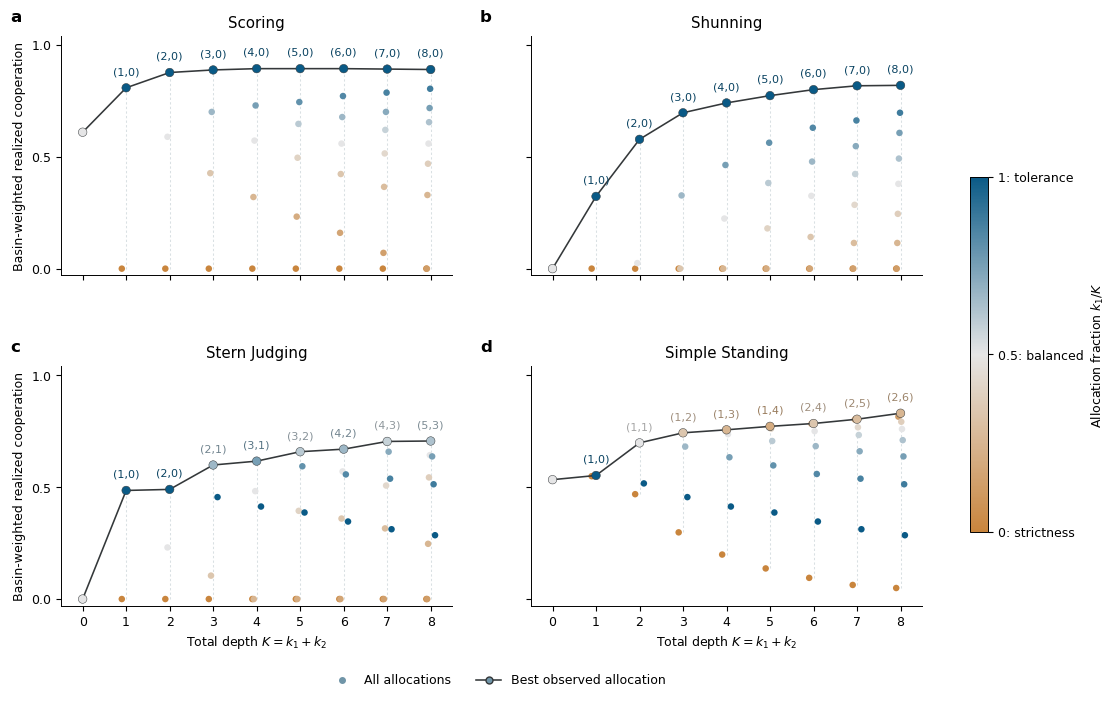

Saved four panels and one combined figure in PDF and SVG.


In [5]:
for norm in NORM_ORDER:
    fig,ax=plt.subplots(figsize=(5.7,3.7))
    fig.subplots_adjust(left=.13,right=.73,bottom=.24,top=.87)
    draw_panel(ax,norm)
    add_colorbar(fig,fig.add_axes([.77,.29,.025,.49]))
    fig.legend(handles=HANDLES,loc='lower center',bbox_to_anchor=(.46,.02),
               ncol=2,frameon=False,fontsize=8)
    save_figure(fig,f'panel_{norm}')
    plt.close(fig)

fig,axes=plt.subplots(2,2,figsize=(11.8,7.4),sharex=True,sharey=True)
fig.subplots_adjust(left=.08,right=.81,bottom=.16,top=.93,wspace=.20,hspace=.38)
for index,(ax,norm) in enumerate(zip(axes.flat,NORM_ORDER)):
    draw_panel(ax,norm,'abcd'[index])
    if index%2: ax.set_ylabel('')
    if index<2: ax.set_xlabel('')
add_colorbar(fig,fig.add_axes([.85,.26,.016,.48]))
fig.legend(handles=HANDLES,loc='lower center',bbox_to_anchor=(.45,.035),
           ncol=2,frameon=False,fontsize=9)
save_figure(fig,'Figure4_combined')
plt.show()
plt.close(fig)
assert len(list(FIGURES.glob('*.pdf'))) == len(list(FIGURES.glob('*.svg'))) == 5
print('Saved four panels and one combined figure in PDF and SVG.')